In [84]:
import pandas as pd
import numpy as np
np.random.seed(42)
n=5000
##generate random data
data ={ 
  "customer_id":range (1001,1001+n),
  "age": np.random.randint(18,75,n),
  "gender": np.random.choice(["Male","Female"],n),
  "tenure_months": np.random.randint(1,73,n),
  "monthly_charges": np.random.uniform(20,150,n).round(2),
  "contract_type": np.random.choice(["Month-to-month","One year","Two year"],n,
                                     p=[0.55,0.25,0.20]),
  "internet_service":np.random.choice(["DSL","Fibre optic","No_Service"],n),
  "payment_method":np.random.choice(["Electronic","Credit card","Bank transfer"],n),
  "support_calls":np.random.poisson(2,n),
  "total_charges":np.zeros(n)
}
##calculate total charges
df= pd.DataFrame(data)
df["total_charges"]= df["monthly_charges"]*df["tenure_months"].round(2)

##generate customer churn probability
churn_score = (0.15+0.12*(df["contract_type"]=="Month-to-month")+0.08*(df["tenure_months"]<12)+0.08*(df["support_calls"]>3))
churn_probability = np.clip(churn_score,0,0.9)

##generate churn outcome
df["churn"]=np.random.binomial(1,churn_probability)

##save dataset
df.to_csv("customer_churn.csv",index=False)
print("Dataset generated successfully")
print("Total Customers:",len(df))
print(df.head())

Dataset generated successfully
Total Customers: 5000
   customer_id  age  gender  tenure_months  monthly_charges   contract_type  \
0         1001   56    Male             28            42.83  Month-to-month   
1         1002   69    Male              5            74.78  Month-to-month   
2         1003   46  Female             21           123.20        Two year   
3         1004   32  Female             18            80.43        One year   
4         1005   60    Male             47            89.88  Month-to-month   

  internet_service payment_method  support_calls  total_charges  churn  
0       No_Service  Bank transfer              2        1199.24      0  
1      Fibre optic     Electronic              1         373.90      1  
2              DSL    Credit card              5        2587.20      0  
3              DSL    Credit card              1        1447.74      0  
4       No_Service     Electronic              5        4224.36      0  


In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print ("Libraries imported successfully")

Libraries imported successfully


In [87]:
df = pd.read_csv("customer_churn.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [88]:
df.head()

,customer_id,age,gender,tenure_months,monthly_charges,contract_type,internet_service,payment_method,support_calls,total_charges,churn
0,1001,56,Male,28,42.83,Month-to-month,No_Service,Bank transfer,2,1199.24,0
1,1002,69,Male,5,74.78,Month-to-month,Fibre optic,Electronic,1,373.90,1
2,1003,46,Female,21,123.20,Two year,DSL,Credit card,5,2587.20,0
3,1004,32,Female,18,80.43,One year,DSL,Credit card,1,1447.74,0
4,1005,60,Male,47,89.88,Month-to-month,No_Service,Electronic,5,4224.36,0


In [89]:
df.shape

(5000, 11)

In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       5000 non-null   int64  
 1   age               5000 non-null   int64  
 2   gender            5000 non-null   str    
 3   tenure_months     5000 non-null   int64  
 4   monthly_charges   5000 non-null   float64
 5   contract_type     5000 non-null   str    
 6   internet_service  5000 non-null   str    
 7   payment_method    5000 non-null   str    
 8   support_calls     5000 non-null   int64  
 9   total_charges     5000 non-null   float64
 10  churn             5000 non-null   int64  
dtypes: float64(2), int64(5), str(4)
memory usage: 603.0 KB


In [91]:
df.describe()

,customer_id,age,tenure_months,monthly_charges,support_calls,total_charges,churn
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000
mean,3500.500000,46.148600,36.616600,85.186860,1.975200,3131.79291,0.234800
std,1443.520003,16.325753,20.938101,37.896976,1.409746,2413.84559,0.423916
min,1001.000000,18.000000,1.000000,20.020000,0.000000,23.21000,0.000000
25%,2250.750000,32.000000,18.000000,52.040000,1.000000,1189.23000,0.000000
50%,3500.500000,46.000000,37.000000,84.685000,2.000000,2510.69000,0.000000
75%,4750.250000,60.000000,55.000000,118.972500,3.000000,4581.19500,0.000000
max,6000.000000,74.000000,72.000000,149.960000,9.000000,10720.80000,1.000000


In [92]:

df.isnull().sum()

customer_id         0
age                 0
gender              0
tenure_months       0
monthly_charges     0
contract_type       0
internet_service    0
payment_method      0
support_calls       0
total_charges       0
churn               0
dtype: int64

In [98]:
df.duplicated().sum()

np.int64(0)

In [99]:
x= ["internet_service","contract_type","payment_method"]

In [100]:
for i in x:
    p=df[i].value_counts()
    print(p)
    print("Percentages")
    print(p/5000*100)

internet_service
DSL            1768
No_Service     1644
Fibre optic    1588
Name: count, dtype: int64
Percentages
internet_service
DSL            35.36
No_Service     32.88
Fibre optic    31.76
Name: count, dtype: float64
contract_type
Month-to-month    2707
One year          1301
Two year           992
Name: count, dtype: int64
Percentages
contract_type
Month-to-month    54.14
One year          26.02
Two year          19.84
Name: count, dtype: float64
payment_method
Bank transfer    1752
Electronic       1633
Credit card      1615
Name: count, dtype: int64
Percentages
payment_method
Bank transfer    35.04
Electronic       32.66
Credit card      32.30
Name: count, dtype: float64


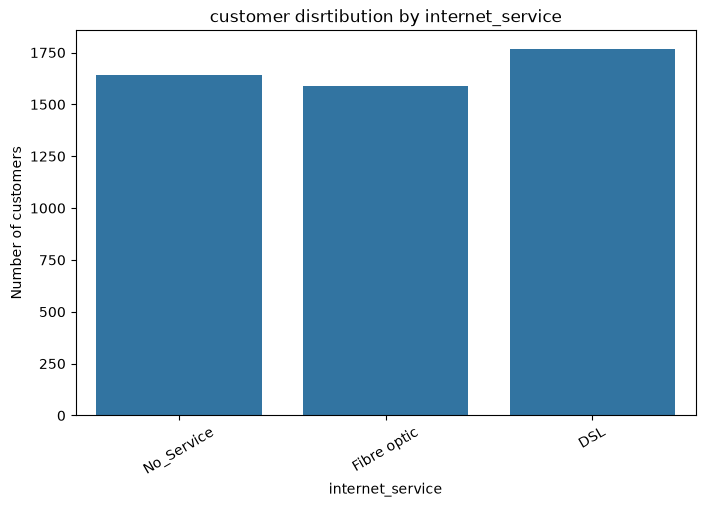

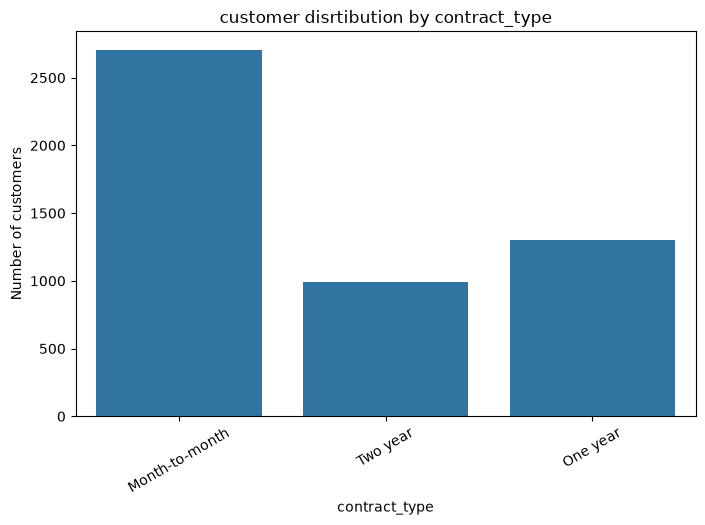

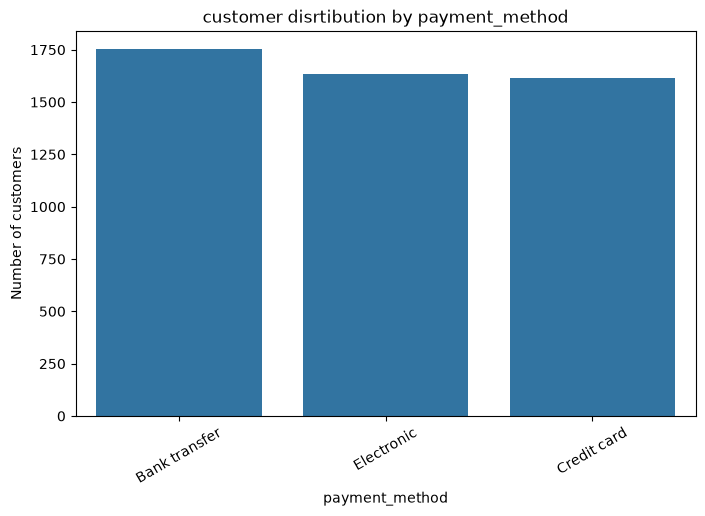

In [101]:
for i in x:
    plt.figure(figsize=(8,5))
    sns.countplot(data=df,x=i)
    plt.title(f"customer disrtibution by {i}")
    plt.xlabel(i)
    plt.ylabel("Number of customers")
    plt.xticks(rotation=30)

In [102]:
df["churn"].value_counts()

churn
0    3826
1    1174
Name: count, dtype: int64

In [103]:
churn_contract = df.groupby("contract_type")["churn"].mean()*100

print("churn_contract")

churn_contract


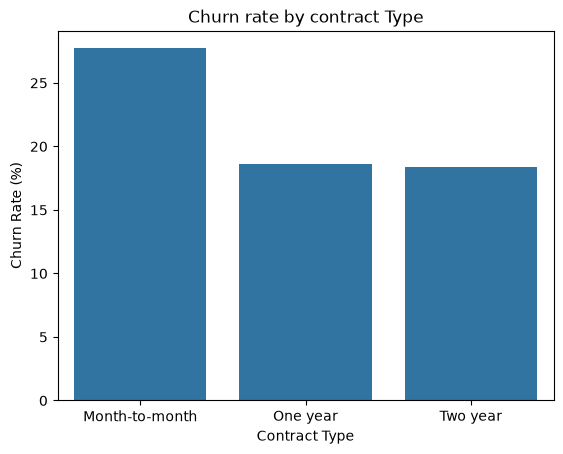

In [104]:
sns.barplot(x=churn_contract.index,y=churn_contract.values)
plt.title("Churn rate by contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

In [105]:
print(churn_contract.round(2))

contract_type
Month-to-month    27.71
One year          18.60
Two year          18.35
Name: churn, dtype: float64


In [106]:
churn_payment = df.groupby("payment_method")["churn"].mean()*100
print("churn_payment")

churn_payment


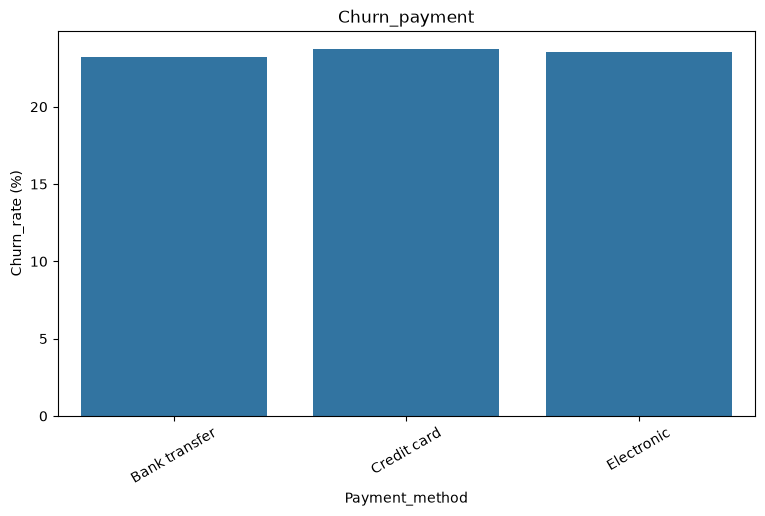

In [107]:
plt.figure(figsize=(9,5))
sns.barplot(x =churn_payment.index,y=churn_payment.values)
plt.title("Churn_payment")
plt.xlabel("Payment_method")
plt.ylabel("Churn_rate (%)")
plt.xticks(rotation =30)
plt.show()



In [108]:
print(churn_payment.round(2))

payment_method
Bank transfer    23.23
Credit card      23.72
Electronic       23.52
Name: churn, dtype: float64


In [109]:
churn_internet = df.groupby("internet_service")["churn"].mean()*100
print("churn_internet")

churn_internet


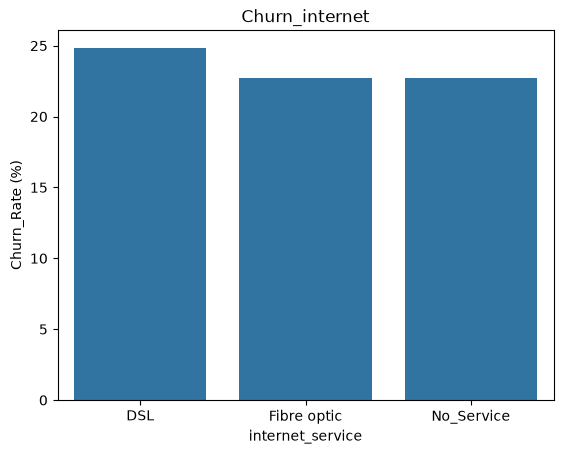

In [110]:
sns.barplot(x=churn_internet.index,y=churn_internet.values)
plt.title("Churn_internet")
plt.xlabel("internet_service")
plt.ylabel("Churn_Rate (%)")
plt.show()

In [78]:
print(churn_internet.round(2))

internet_service
DSL            89.76
Fibre optic    90.37
Unknown        90.33
Name: churn, dtype: float64


In [111]:
df["churn"].value_counts()

churn
0    3826
1    1174
Name: count, dtype: int64

In [112]:
df["churn"].value_counts(normalize=True).mul(100).round(2)

churn
0    76.52
1    23.48
Name: proportion, dtype: float64